# Sentence Embedding Retrieval Experiment

This experiment evaluates sentence embeddings as a semantic retrieval
method for mapping cyber threat intelligence sentences to MITRE ATT&CK
techniques.

Unlike Bag-of-Words and TF-IDF, which primarily rely on lexical overlap,
sentence embeddings represent text as dense numerical vectors intended to
capture semantic meaning.

The same MITRE ATT&CK retrieval corpus and TRAM evaluation queries used in
the previous experiments are retained to ensure a fair comparison.

Each MITRE ATT&CK technique and TRAM threat sentence is encoded as a dense
vector using a pretrained Sentence Transformer model. Cosine similarity is
then used to rank ATT&CK techniques for each query.

Performance is evaluated using:
- Recall@1
- Recall@5
- Recall@10
- Mean Reciprocal Rank (MRR)

In [2]:
import pandas as pd
import numpy as np
import re

from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

W1020 11:25:04.086000 52515 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


- using all-MiniLM-L6-v2 as our semantic embedding model. used ChatGPT for model suggestion

In [3]:
from sentence_transformers import SentenceTransformer
model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [4]:
import pandas as pd
#load data
mitre_df = pd.read_csv(
    "mitre_techniques.csv"
)

tram_df = pd.read_csv(
    "tram_single_label_compatible.csv"
)

In [5]:
#check
print("MITRE corpus:", mitre_df.shape)
print("TRAM queries:", tram_df.shape)

MITRE corpus: (697, 7)
TRAM queries: (3077, 5)


In [6]:
#same mitre retrieval text
def clean_mitre_text(text):
    text = str(text)

    # Remove MITRE citations
    text = re.sub(
        r"\(Citation:[^)]+\)",
        "",
        text
    )

    # Convert Markdown links to visible text
    text = re.sub(
        r"\[([^\]]+)\]\([^)]+\)",
        r"\1",
        text
    )

    # Remove Markdown backticks
    # while preserving their contents
    text = text.replace("`", "")

    # Normalize whitespace
    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip()

In [7]:
mitre_df["retrieval_text"] = (
    mitre_df["name"].fillna("")
    + ". "
    + mitre_df["description"].fillna("")
)

mitre_df["retrieval_text"] = (
    mitre_df["retrieval_text"]
    .apply(clean_mitre_text)
)

In [8]:
#tram
tram_df["query_text"] = (
    tram_df["sentence"]
    .fillna("")
    .str.strip()
)

**NOTE**

- not stemming or lemmatizing or removing stop words
- we want the natural language for the sentence transformer

In [9]:
#encode the MITRE corpus
mitre_embeddings = model.encode(
    mitre_df["retrieval_text"].tolist(),
    show_progress_bar=True
)

Batches:   0%|          | 0/22 [00:00<?, ?it/s]

In [10]:
print(
    "MITRE embedding shape:",
    mitre_embeddings.shape
)

MITRE embedding shape: (697, 384)


- the 697 ATT&CK techniques are each represented by 384 numerical

In [11]:
#encode tram
query_embeddings = model.encode(
    tram_df["query_text"].tolist(),
    show_progress_bar=True
)

Batches:   0%|          | 0/97 [00:00<?, ?it/s]

In [12]:
print(
    "Query embedding shape:",
    query_embeddings.shape
)

Query embedding shape: (3077, 384)


In [13]:
#test one query first
query_index = 0

query_text = tram_df.iloc[
    query_index
]["query_text"]

ground_truth = tram_df.iloc[
    query_index
]["technique_id"]

print("QUERY:")
print(query_text)

print("\nGROUND TRUTH:")
print(ground_truth)

QUERY:
It spreads to Microsoft Windows machines using several propagation methods, including the EternalBlue exploit for the CVE-2017-0144 vulnerability in the SMB service.

GROUND TRUTH:
T1210


In [14]:
#similarity
scores = cosine_similarity(
    query_embeddings[
        query_index
    ].reshape(1, -1),
    mitre_embeddings
).flatten()

In [15]:
top_indices = np.argsort(
    scores
)[::-1][:10]

In [16]:
print(
    "Top 10 embedding results:\n"
)

for rank, idx in enumerate(
    top_indices,
    start=1
):
    print(
        f"{rank}. "
        f"{mitre_df.iloc[idx]['technique_id']} - "
        f"{mitre_df.iloc[idx]['name']} "
        f"(score={scores[idx]:.4f})"
    )

print(
    "\nCorrect technique:",
    ground_truth
)

Top 10 embedding results:

1. T1216.002 - SyncAppvPublishingServer (score=0.5329)
2. T1482 - Domain Trust Discovery (score=0.4722)
3. T1546.007 - Netsh Helper DLL (score=0.4716)
4. T1127.001 - MSBuild (score=0.4687)
5. T1218.010 - Regsvr32 (score=0.4645)
6. T1187 - Forced Authentication (score=0.4610)
7. T1543.003 - Windows Service (score=0.4596)
8. T1559.002 - Dynamic Data Exchange (score=0.4529)
9. T1218.003 - CMSTP (score=0.4512)
10. T1218 - System Binary Proxy Execution (score=0.4504)

Correct technique: T1210


**Just like TF-IDF, calculate similarity for all queries**

In [17]:
similarity_matrix = cosine_similarity(
    query_embeddings,
    mitre_embeddings
)

In [18]:
print(
    "Similarity matrix:",
    similarity_matrix.shape
)

Similarity matrix: (3077, 697)


In [19]:
#technique look up
id_to_index = {
    technique_id: idx
    for idx, technique_id
    in enumerate(
        mitre_df["technique_id"]
    )
}

In [20]:
#ground truth rank
ranks = []

for i in range(len(tram_df)):

    ground_truth = tram_df.iloc[i][
        "technique_id"
    ]

    correct_index = id_to_index[
        ground_truth
    ]

    scores = similarity_matrix[i]

    ranked_indices = np.argsort(
        scores
    )[::-1]

    correct_rank = (
        np.where(
            ranked_indices
            == correct_index
        )[0][0]
        + 1
    )

    ranks.append(
        correct_rank
    )

In [21]:
tram_df["embedding_rank"] = ranks
tram_df[
    [
        "sentence",
        "technique_id",
        "embedding_rank"
    ]
].head(10)

,sentence,technique_id,embedding_rank
0,It spreads to Microsoft Windows machines using...,T1210,24
1,"Once a machine is infected by NotPetya, a seri...",T1570,20
2,Ransomware DLL C:\windows\perfc.dat,T1140,27
3,The malware decompresses its resource named 0x...,T1140,14
4,The malware is a DLL that is launched using ru...,T1218.011,2
5,It is executed with the following arguments: #...,T1057,18
6,The credential theft module is dropped if the ...,T1106,212
7,The malware decompresses a resource (0x1 if th...,T1140,16
8,It calls OpenProcess on lsass.exe with access ...,T1003.001,1
9,"Server service, which both enforces security p...",T1003.001,2


**calulate the metrics**

In [22]:
#recall @1
recall_at_1 = (
    tram_df["embedding_rank"] <= 1
).mean()

In [23]:
#recall at 5
recall_at_5 = (
    tram_df["embedding_rank"] <= 5
).mean()

In [24]:
#recall !10
recall_at_10 = (
    tram_df["embedding_rank"] <= 10
).mean()

In [25]:
#mrr
mrr = (
    1 / tram_df["embedding_rank"]
).mean()

In [26]:
print(f"Recall@1:  {recall_at_1:.3f}")
print(f"Recall@5:  {recall_at_5:.3f}")
print(f"Recall@10: {recall_at_10:.3f}")
print(f"MRR:       {mrr:.3f}")

Recall@1:  0.149
Recall@5:  0.359
Recall@10: 0.463
MRR:       0.253


In [29]:
#comparison
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Metric": [
        "Recall@1",
        "Recall@5",
        "Recall@10",
        "MRR"
    ],
    "Bag-of-Words": [
        0.100422,
        0.244394,
        0.324017,
        0.177347
    ],
    "TF-IDF": [
        0.129347,
        0.304517,
        0.399415,
        0.220974
    ],
    "Sentence Embeddings": [
        0.149,
        0.359,
        0.463,
        0.253
    ]
})

comparison

,Metric,Bag-of-Words,TF-IDF,Sentence Embeddings
0,Recall@1,0.100422,0.129347,0.149
1,Recall@5,0.244394,0.304517,0.359
2,Recall@10,0.324017,0.399415,0.463
3,MRR,0.177347,0.220974,0.253


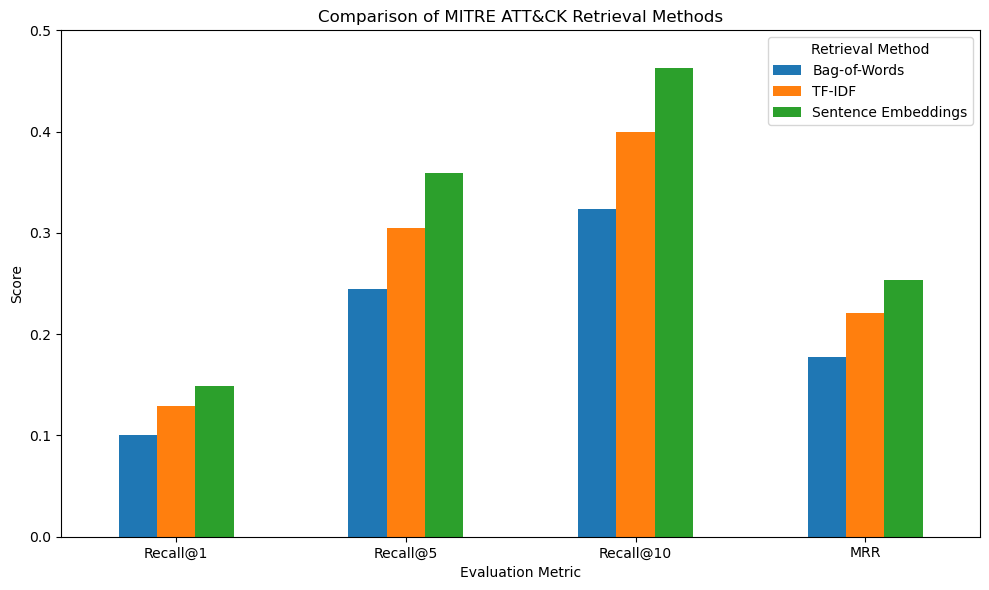

In [30]:
comparison.set_index("Metric").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Comparison of MITRE ATT&CK Retrieval Methods"
)

plt.ylabel("Score")
plt.xlabel("Evaluation Metric")

plt.ylim(0, 0.5)

plt.xticks(rotation=0)

plt.legend(
    title="Retrieval Method"
)

plt.tight_layout()
plt.show()

In [32]:
#save embedding results
embedding_summary = pd.DataFrame({
    "method": [
        "Sentence Embeddings"
    ],
    "model": [
        "all-MiniLM-L6-v2"
    ],
    "recall@1": [
        recall_at_1
    ],
    "recall@5": [
        recall_at_5
    ],
    "recall@10": [
        recall_at_10
    ],
    "mrr": [
        mrr
    ]
})

In [33]:
embedding_summary.to_csv(
    "embedding_summary.csv",
    index=False
)
print ("saved!")

saved!


In [34]:
#save query results
embedding_query_results = tram_df[
    [
        "sentence",
        "technique_id",
        "embedding_rank",
        "split"
    ]
].copy()
embedding_query_results.to_csv(
    "embedding_query_results.csv",
    index=False
)

print("Embedding results saved!")

Embedding results saved!


Sentence embeddings achieved the highest retrieval performance across all four evaluation metrics, followed by TF-IDF and Bag-of-Words. Recall@5 increased from 24.4% using Bag-of-Words to 30.5% using TF-IDF and 35.9% using sentence embeddings. Similarly, Recall@10 increased from 32.4% to 39.9% and 46.3%, respectively. These results suggest that both term weighting and semantic representation improve ATT&CK retrieval. However, the relatively low Recall@1 of 14.9% for sentence embeddings also indicates that accurately distinguishing the single best ATT&CK technique remains challenging.